# Ettin: longer, diverse backbone training

Self-contained **A100 / VS Code Colab** notebook. All model, data, training, checkpoint and evaluation code is editable inline.
Train the **whole Ettin backbone**, with 128/256/384D Matryoshka retrieval, external frozen GTE supervision,
and a later phase containing 1,024-token passages. This replaces the short MS MARCO pilot; its saved outputs are preserved
in `archive/02_ettin_pilot.ipynb` in the repository. Old Drive runs are never overwritten.

**Defaults:** continue your validation-best Ettin-32M pilot; up to 10,000 optimizer updates with early stopping; Natural Questions + SQuAD + AllNLI;
64-example batches at 512 tokens, alternating with 32-example 1,024-token batches after update 6,000.
Validation selects the checkpoint; NanoBEIR and the bottom-cell sanity check report quality after selection.

The default `research_continuation` mode loads the pilot's best backbone and alignment weights, retaining its MS MARCO history.
No new MS MARCO/GooAQ rows are used. Set `INIT_MODE='pretrained'` for a separate run without the project pilot lineage.
Model licenses and data licenses are separate: read the licensing cell below. No claim of SOTA reproduction or legal clearance.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Install into this notebook's kernel. Keep Colab's CUDA-enabled PyTorch.
# Restart the kernel after this cell if it already imported different versions.
%pip install -q transformers==5.1.0 datasets==4.5.0 accelerate==1.12.0 sentence-transformers==5.2.2 safetensors
%pip install -q scikit-learn==1.7.2 matplotlib

In [7]:
import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HOME'] = '/content/hf-cache' if os.path.isdir('/content') else '/tmp/encoder-hf-cache'
import copy, gc, hashlib, json, math, random, shutil, time, uuid
from pathlib import Path
from collections import defaultdict
from contextlib import nullcontext
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
from transformers import AutoConfig, AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file, save_file
from tqdm.auto import tqdm
from google.colab import drive

drive.mount('/content/drive')
DEVICE = 'cuda'
assert torch.cuda.is_available(), 'Select an A100 GPU runtime in Colab.'
assert torch.cuda.is_bf16_supported(), 'This notebook uses BF16 on a supported GPU.'
print(torch.cuda.get_device_name(), 'PyTorch:', torch.__version__)
torch.set_float32_matmul_precision('high')
import csv
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NVIDIA A100-SXM4-40GB PyTorch: 2.11.0+cu128


## Settings and source lineage

Choose a fresh `RUN_NAME` whenever changing configuration. Defaults continue your existing pilot for research.
Check `SOURCE_RUN` points to its Drive folder. This retains its MS MARCO training history; changing data does not erase it.
To initialize from the pinned pretrained weights instead, set `INIT_MODE='pretrained'` and choose another run name.
A fresh run peaks at 3e-5; research continuation peaks at 1e-5. Both train all backbone layers.

Smoke settings: steps 12, long phase after 6, batch sizes 4/2, source caps 32, holdouts 4,
shuffle buffer 100, scan limit 10,000, eval/checkpoint every 4, early-stop minimum 8.

In [8]:
RUN_NAME = 'ettin-backbone-diverse-01'
INIT_MODE = 'research_continuation'  # user-selected; or 'pretrained' for a separate initialization
SOURCE_RUN = Path('/content/drive/MyDrive/encoder_experiments/ettin-pilot-01')
SOURCE_STAGE = 'student'
SOURCE_CHOICE = 'best'
ROOT = Path('/content/drive/MyDrive/encoder_experiments') / RUN_NAME
LOCAL = Path('/content/encoder-work') / RUN_NAME
assert ROOT.resolve()!=SOURCE_RUN.resolve()
ROOT.mkdir(parents=True,exist_ok=True);LOCAL.mkdir(parents=True,exist_ok=True)
CFG = dict(experiment='ettin', recipe='diverse-backbone-v2', seed=44, ettin_size='32m',
           student_steps=10000, batch_size=64, long_batch_size=32, max_length=1024,
           short_length=512, long_start=6000, teacher_batch_size=16, eval_batch_size=32,
           student_lr=3e-5 if INIT_MODE=='pretrained' else 1e-5, weight_decay=.01,
           warmup_steps=300, min_lr_ratio=.1, temperature=.05,
           alignment_weight=.25, relational_weight=.2, false_negative_margin=.05, max_full_mrr_drop=.02,
           gradient_checkpointing=True, eval_every=250, checkpoint_every=100, log_every=25,
           patience=6, min_delta=.001, min_stop_step=6500,
           validation_rows=128, test_rows=128, shuffle_buffer=10000, scan_limit=800000,
           max_text_chars=24000, mining_pool=8192, mining_candidates=8)
DIMS=[128,256,384]
MIX_CYCLE=['nq','squad','all_nli','nq','squad']  # 40/40/20, equal per-source validation weights
EVAL_LENGTHS=[256,1024]  # fixed throughout training, independent of the current training phase
SOURCE_CAPS=dict(nq=60000,squad=40000,all_nli=60000)
GTE=dict(id='Alibaba-NLP/gte-modernbert-base',revision='e7f32e3c00f91d699e8c43b53106206bcc72bb22')
ETTIN=dict(id='jhu-clsp/ettin-encoder-32m',revision='1b8ba06455dd44f80fc9c1ca9e22806157a57379')
DATA_SPECS={
 'nq':dict(id='sentence-transformers/natural-questions',revision='f9e894e1081e206e577b4eaa9ee6de2b06ae6f17',subset='pair',split='train'),
 'squad':dict(id='sentence-transformers/squad',revision='d84c8c2ef64693264c890bb242d2e73fc0a46c40',subset='pair',split='train'),
 'all_nli':dict(id='sentence-transformers/all-nli',revision='d482672c8e74ce18da116f430137434ba2e52fab',subset='triplet',split='train'),
}
NANO=dict(id='sentence-transformers/NanoBEIR-en',revision='beb106fbcfaa599c508c667041bf8c85fd78736b')
BENCHMARK_NAMES=['NanoNQ','NanoHotpotQA']  # no NanoMSMARCO under the default data policy
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG['seed'])
def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
def text_id(s):
    return hashlib.sha256(' '.join(s.split()).casefold().encode()).hexdigest()
def write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp-' + uuid.uuid4().hex)
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False))
    os.replace(tmp, path)
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''): h.update(chunk)
    return h.hexdigest()


assert INIT_MODE in ('pretrained','research_continuation')
assert set(MIX_CYCLE)==set(DATA_SPECS)==set(SOURCE_CAPS)
assert CFG['student_steps']>0 and 0<=CFG['long_start']<CFG['student_steps']
assert 0<CFG['min_stop_step']<=CFG['student_steps']
assert 1<min(CFG['batch_size'],CFG['long_batch_size'])<=min(SOURCE_CAPS.values())
assert max(EVAL_LENGTHS)<=CFG['max_length'] and CFG['short_length']<=CFG['max_length']
print('Destination:',ROOT,'\nInitialization:',INIT_MODE,'\nMaximum updates:',CFG['student_steps'])

Destination: /content/drive/MyDrive/encoder_experiments/ettin-backbone-diverse-01 
Initialization: research_continuation 
Maximum updates: 10000


## Research basis and licensing review (2026-09-24)

Borrowed techniques, scaled to one A100: task-diverse contrastive batches, mined negatives and false-negative filtering
([Qwen3 training guide](https://github.com/QwenLM/Qwen3-Embedding/blob/main/docs/training/SWIFT.md)),
and dimension Matryoshka training ([Nomic v1.5](https://huggingface.co/nomic-ai/nomic-embed-text-v1.5)).
[GTE's model card](https://huggingface.co/Alibaba-NLP/gte-modernbert-base) supplies the external supervisor and published CLS pooling.
This is a small-encoder adaptation of those ideas, not their billion-pair/distributed training recipe.

| Component | Terms checked | Treatment here |
|---|---|---|
| Ettin-32M | [MIT model license](https://huggingface.co/jhu-clsp/ettin-encoder-32m) | Keep model card/license with export |
| GTE-ModernBERT-base | [Apache-2.0 model license](https://huggingface.co/Alibaba-NLP/gte-modernbert-base) | Frozen external supervision; retain attribution |
| SQuAD | [CC BY-SA 4.0 upstream](https://rajpurkar.github.io/SQuAD-explorer/) | Attribution and ShareAlike terms retained |
| Natural Questions | [CC BY-SA 3.0 data](https://huggingface.co/datasets/google-research-datasets/natural_questions); repository code is Apache-2.0 | Do not confuse code license with Wikipedia-derived data license |
| AllNLI: SNLI | [CC BY-SA 4.0](https://nlp.stanford.edu/projects/snli/) | Preserve upstream attribution and ShareAlike notice |
| AllNLI: MultiNLI | [Paper §2.3](https://aclanthology.org/N18-1101.pdf): OANC permissive terms, CC BY/SA 3.0 fiction, some US public-domain texts | Record mixed terms and territorial qualification; not blanket Apache/MIT |
| NanoHotpotQA | [CC BY-SA 4.0 upstream](https://hotpotqa.github.io/) | Evaluation only |
| NanoNQ | Same Natural Questions terms | Evaluation only; exact overlaps excluded |

These data terms allow commercial use subject to their conditions; they are **not obligation-free licenses**.
The notebook saves pinned cards, upstream links and transformation notes. Derived data are for your run and are not bundled
into inference exports. Attribution/ShareAlike obligations for redistributed data remain; this review does not determine
whether a trained weight artifact is an adaptation under each license, or audit all upstream pretraining content.

Excluded defaults: [MS MARCO](https://microsoft.github.io/msmarco/Notice.html) and [GooAQ](https://github.com/allenai/gooaq)
(non-commercial upstream terms); wholesale [NVIDIA embedding training collection](https://huggingface.co/datasets/nvidia/embed-nemotron-dataset-v1)
(research/development statement, mixed terms and additional Llama-generated-data conditions);
Stack Exchange wrappers (missing per-post attribution/version metadata); S2ORC (blanket license insufficient for all source papers).
The default research continuation records the old pilot's MS MARCO history; it is not represented as a commercially cleared artifact.

In [9]:
LICENSE_RECORD=dict(review_date='2026-09-24',models={'ettin':'MIT','gte':'Apache-2.0'},
 datasets={
  'squad':dict(terms=['CC-BY-SA-4.0'],upstream=['https://rajpurkar.github.io/SQuAD-explorer/']),
  'nq':dict(terms=['CC-BY-SA-3.0'],upstream=['https://huggingface.co/datasets/google-research-datasets/natural_questions','https://github.com/google-research-datasets/natural-questions']),
  'all_nli':dict(terms=['SNLI: CC-BY-SA-4.0','MultiNLI: OANC terms; CC-BY-3.0; CC-BY-SA-3.0; US public domain'],
                 upstream=['https://nlp.stanford.edu/projects/snli/','https://aclanthology.org/N18-1101.pdf']),
 },benchmarks={'NanoNQ':'Natural Questions: CC-BY-SA-3.0','NanoHotpotQA':'CC-BY-SA-4.0'},
 excluded=['MS MARCO','GooAQ','wholesale NVIDIA embed-nemotron-dataset-v1','Stack Exchange wrappers','S2ORC'],
 transformations='Normalize whitespace for identities; group/split/filter; mine lexical training negatives; tokenize/truncate at runtime.',
 obligations='Retain attribution, source links, changes and applicable ShareAlike notices when redistributing adapted data. No blanket license assigned to derived weights.',
 lineage='Old MS MARCO-trained pilot retained' if INIT_MODE=='research_continuation' else 'Pinned pretrained Ettin; no project MS MARCO pilot loaded')
source_info=dict(mode=INIT_MODE,model=ETTIN)
source_state=None
if INIT_MODE=='research_continuation':
    source_contract=json.loads((SOURCE_RUN/'config.json').read_text())
    assert source_contract['ettin']==ETTIN and source_contract['gte']==GTE
    def read_source(path):
        meta=json.loads((path/'COMMITTED.json').read_text())
        assert meta['contract']==digest(source_contract)
        local=LOCAL/'source.pt';shutil.copyfile(path/'state.pt',local)
        assert file_sha(local)==meta['sha256']
        state=torch.load(local,map_location='cpu',weights_only=False)
        assert state['contract']==meta['contract'] and state['step']==meta['step']
        assert state['family']=='ettin' and state['stage']==SOURCE_STAGE
        return state,meta
    lock=ROOT/'source.json'
    if lock.exists():
        source_info=json.loads(lock.read_text())
        assert source_info['mode']==INIT_MODE and source_info['run']==str(SOURCE_RUN) and source_info['choice']==SOURCE_CHOICE and source_info['stage']==SOURCE_STAGE
        source_state,meta=read_source(Path(source_info['checkpoint']));assert meta['sha256']==source_info['sha256']
    else:
        parent=SOURCE_RUN/'checkpoints'/SOURCE_STAGE
        candidates=sorted((p for p in parent.iterdir() if not p.name.startswith('.') and (p/'COMMITTED.json').exists()),reverse=True)
        for path in candidates:
            try:source_state,meta=read_source(path);break
            except (OSError,ValueError,AssertionError,EOFError):continue
        assert source_state is not None, 'No valid source checkpoint.'
        selected=source_state['best_step'] if SOURCE_CHOICE=='best' else source_state['step'] if SOURCE_CHOICE=='latest' else int(SOURCE_CHOICE)
        if source_state['step']!=selected:
            path=next(p for p in candidates if int(p.name.split('-')[0])==selected)
            source_state,meta=read_source(path)
        source_info=dict(mode=INIT_MODE,run=str(SOURCE_RUN),stage=SOURCE_STAGE,choice=SOURCE_CHOICE,data_id=source_state['data_id'],
                         step=selected,checkpoint=str(path),sha256=meta['sha256'],model=ETTIN)
        write_json(lock,source_info)
contract=dict(config=CFG,ettin=ETTIN,gte=GTE,data=DATA_SPECS,nano=NANO,source=source_info,
              source_caps=SOURCE_CAPS,mix_cycle=MIX_CYCLE,dimensions=DIMS,eval_lengths=EVAL_LENGTHS,
              benchmark_names=BENCHMARK_NAMES,licenses=LICENSE_RECORD,implementation=2)
CONTRACT_ID=digest(contract)
if (ROOT/'config.json').exists():assert json.loads((ROOT/'config.json').read_text())==contract, 'Settings changed: choose a new RUN_NAME.'
else:write_json(ROOT/'config.json',contract)
write_json(ROOT/'LICENSE_PROVENANCE.json',LICENSE_RECORD)
# Save exact pinned model/dataset cards and available license files, not just mutable URLs.
NOTICE_DIR=ROOT/'notices';NOTICE_DIR.mkdir(exist_ok=True)
for name,spec,kind in [('ettin',ETTIN,'model'),('gte',GTE,'model')]+[(k,v,'dataset') for k,v in DATA_SPECS.items()]+[('nano',NANO,'dataset')]:
    card=hf_hub_download(spec['id'],'README.md',revision=spec['revision'],repo_type=kind)
    shutil.copyfile(card,NOTICE_DIR/f'{name}-README.md')
# Hugging Face's typed missing-file exception lets network/auth failures remain visible.
from huggingface_hub.errors import EntryNotFoundError
for name,spec in [('ettin',ETTIN),('gte',GTE)]:
    for filename in ['LICENSE','LICENSE.txt']:
        try:lic=hf_hub_download(spec['id'],filename,revision=spec['revision'])
        except EntryNotFoundError:continue
        shutil.copyfile(lic,NOTICE_DIR/f'{name}-{filename}')
print('Recorded license provenance and initialization:',source_info)
EMBEDDED_MODEL_NOTICES = {'ettin-MIT.txt': {'text': 'MIT License\n\nCopyright (c) 2025 Johns Hopkins University Center for Language and Speech Processing\n\nPermission is hereby granted, free of charge, to any person obtaining a copy\nof this software and associated documentation files (the "Software"), to deal\nin the Software without restriction, including without limitation the rights\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\ncopies of the Software, and to permit persons to whom the Software is\nfurnished to do so, subject to the following conditions:\n\nThe above copyright notice and this permission notice shall be included in all\ncopies or substantial portions of the Software.\n\nTHE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE\nSOFTWARE. ', 'url': 'https://raw.githubusercontent.com/JHU-CLSP/ettin-encoder-vs-decoder/6cbf954a2ecaa7c753be6468a1bccdef401d5f93/LICENSE'}, 'Apache-2.0.txt': {'text': '\n                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n', 'url': 'https://www.apache.org/licenses/LICENSE-2.0.txt'}}
for name,notice in EMBEDDED_MODEL_NOTICES.items():
    (NOTICE_DIR/name).write_text(notice['text'])
write_json(NOTICE_DIR/'model-license-sources.json',{k:v['url'] for k,v in EMBEDDED_MODEL_NOTICES.items()})


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/40.3k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/14.0k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.28k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/1.93k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.15k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/7.15k [00:00<?, ?B/s]

Recorded license provenance and initialization: {'mode': 'research_continuation', 'run': '/content/drive/MyDrive/encoder_experiments/ettin-pilot-01', 'stage': 'student', 'choice': 'best', 'data_id': '808e89183ca1c2c9aaaa5a91808723ed41e474c94f1fa1f5bc95556168c3ab3e', 'step': 400, 'checkpoint': '/content/drive/MyDrive/encoder_experiments/ettin-pilot-01/checkpoints/student/00000400-88ddf87f', 'sha256': 'baf59fec1759927a51812ce763c61aa3a4d808d21cc84e6330c120b36e2d0cea', 'model': {'id': 'jhu-clsp/ettin-encoder-32m', 'revision': '1b8ba06455dd44f80fc9c1ca9e22806157a57379'}}


## Encoder and frozen external supervisor

In [10]:
def mean_pool(hidden, mask):
    mask = mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden.float()*mask).sum(1) / mask.sum(1).clamp_min(1)

# Input adapters belong to the model, so evaluation, training and export use the same tokenizer/pooling.
class EmbeddingModel(nn.Module):
    def __init__(self, backbone, tokenizer, output_dim, family, spec):
        super().__init__()
        self.backbone, self.tokenizer = backbone, tokenizer
        self.output_dim, self.family, self.spec = output_dim, family, copy.deepcopy(spec)
        self.max_length = CFG['max_length']
        # Ettin's alignment head is training-only. Retrieval always uses its native 384/512 dimensions.
        self.align = nn.Identity() if output_dim == 768 else nn.Linear(output_dim,768,bias=False)
    def forward(self, texts):
        tokens = self.tokenizer(texts, padding=True, truncation=True, max_length=self.max_length,
                                return_tensors='pt').to(next(self.parameters()).device)
        if self.family == 'neobert':
            h = self.backbone(tokens['input_ids'], tokens['attention_mask'])
        else:
            h = self.backbone(**tokens).last_hidden_state
        return mean_pool(h, tokens['attention_mask'])

def count_parameters(model):
    return dict(total=sum(p.numel() for p in model.parameters()),
                backbone=sum(p.numel() for p in model.backbone.parameters()),
                training_only_alignment=sum(p.numel() for p in model.align.parameters()))

def fresh_ettin():
    tok = AutoTokenizer.from_pretrained(ETTIN['id'],revision=ETTIN['revision'])
    backbone = AutoModel.from_pretrained(ETTIN['id'],revision=ETTIN['revision'],attn_implementation='sdpa')
    assert backbone.config.model_type == 'modernbert'
    if CFG['gradient_checkpointing']:
        backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
    return EmbeddingModel(backbone,tok,backbone.config.hidden_size,'ettin',backbone.config.to_dict())
if source_state is None:student=fresh_ettin().to(DEVICE)
else:
    spec=copy.deepcopy(source_state['spec']);typ=spec.pop('model_type');assert typ=='modernbert'
    backbone=AutoModel.from_config(AutoConfig.for_model(typ,**spec),attn_implementation='sdpa')
    tok=AutoTokenizer.from_pretrained(ETTIN['id'],revision=ETTIN['revision'])
    student=EmbeddingModel(backbone,tok,backbone.config.hidden_size,'ettin',source_state['spec']).to(DEVICE)
    student.load_state_dict(source_state['model'],strict=True);del source_state,backbone
    if CFG['gradient_checkpointing']:student.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
student.max_length=CFG['max_length'];student.requires_grad_(True)
assert DIMS==sorted(set(DIMS)) and DIMS[-1]==student.output_dim
assert CFG['max_length']<=student.backbone.config.max_position_embeddings
BASE_WEIGHTS={k:v.detach().cpu().clone() for k,v in student.state_dict().items()}
print(count_parameters(student))

config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

{'total': 32178048, 'backbone': 31883136, 'training_only_alignment': 294912}


In [11]:
class GTEEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.tokenizer = AutoTokenizer.from_pretrained(GTE['id'], revision=GTE['revision'])
        self.backbone = AutoModel.from_pretrained(GTE['id'], revision=GTE['revision'],
                                                  attn_implementation='sdpa', dtype=torch.bfloat16)
        self.output_dim = self.backbone.config.hidden_size
        self.max_length = CFG['max_length']
    def forward(self, texts):
        tokens = self.tokenizer(texts, padding=True, truncation=True, max_length=self.max_length,
                                return_tensors='pt').to(next(self.parameters()).device)
        # Published GTE-ModernBERT uses CLS pooling, not mean pooling.
        return self.backbone(**tokens).last_hidden_state[:,0].float()

supervisor = GTEEncoder().to(DEVICE).eval().requires_grad_(False)
print('Supervisor parameters:', sum(p.numel() for p in supervisor.parameters()))
@torch.no_grad()
def teacher_vectors(texts,length):
    supervisor.eval();supervisor.max_length=length
    parts=[]
    for start in range(0,len(texts),CFG['teacher_batch_size']):
        with torch.autocast('cuda',dtype=torch.bfloat16):z=supervisor(texts[start:start+CFG['teacher_batch_size']])
        parts.append(F.normalize(z.float(),dim=-1))
    result=torch.cat(parts)
    assert torch.isfinite(result).all()
    return result

config.json:   0%|          | 0.00/1.18k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.58M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  298MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

Supervisor parameters: 149014272


## Fixed benchmarks, authored probes and data selection

Train only from the pinned training splits. Holdout assignment is deterministic by positive passage for QA, by anchor
for AllNLI. Reserve held-out text identities across **all** sources before training; exclude exact normalized benchmark
and authored-probe texts. This is not semantic deduplication or an upstream pretraining contamination guarantee.

Data are committed to Drive before training. Re-running reuses the checksum-verified bundle. Lexical negative mining uses
only training positives and avoids all known training positives for each query. GTE screens likely false negatives during
training. AllNLI's explicit contradiction negatives retain their labels. No invented answer padding or unrelated concatenation.

In [12]:
# A pinned, labeled retrieval benchmark. Never used for optimization or early stopping.
BENCHMARKS = {}
def load_benchmarks():
    if BENCHMARKS:
        return BENCHMARKS
    for name in BENCHMARK_NAMES:
        parts = {part: load_dataset('parquet', data_files={'train':f"hf://datasets/{NANO['id']}@{NANO['revision']}/{part}/{name}-*.parquet"}, split='train')
                 for part in ('queries', 'corpus', 'qrels')}
        queries = {str(r['_id']): r['text'] for r in parts['queries'] if r['text'].strip()}
        corpus = {str(r['_id']): r['text'] for r in parts['corpus'] if r['text'].strip()}
        relevant = defaultdict(set)
        for r in parts['qrels']:
            ids = r['corpus-id'] if isinstance(r['corpus-id'], list) else [r['corpus-id']]
            relevant[str(r['query-id'])].update(str(x) for x in ids)
        BENCHMARKS[name] = dict(queries=queries, corpus=corpus, relevant=dict(relevant))
    return BENCHMARKS

@torch.inference_mode()
def encode_texts(model, texts, batch_size=None, dim=None):
    model.eval()
    result = []
    for start in range(0, len(texts), batch_size or CFG['teacher_batch_size']):
        with torch.autocast('cuda', dtype=torch.bfloat16):
            z = model(texts[start:start+(batch_size or CFG['teacher_batch_size'])])
        z = z.float().cpu()
        assert torch.isfinite(z).all(), 'Non-finite embeddings'
        result.append(F.normalize(z[:, :dim], dim=-1) if dim else F.normalize(z, dim=-1))
    return torch.cat(result)

def retrieval_metrics(q, p, relevant, query_ids, corpus_ids):
    scores = q @ p.T
    ranking = scores.argsort(dim=1, descending=True)
    sums = defaultdict(float)
    for i, qid in enumerate(query_ids):
        truth = relevant[qid]
        top = [corpus_ids[j] for j in ranking[i, :10].tolist()]
        hits = [int(x in truth) for x in top]
        sums['hit@1'] += hits[0]
        sums['hit@5'] += bool(sum(hits[:5]))
        sums['recall@10'] += sum(hits) / len(truth)
        sums['mrr@10'] += next((1/(j+1) for j,h in enumerate(hits) if h), 0)
        dcg = sum(h/math.log2(j+2) for j,h in enumerate(hits))
        ideal = sum(1/math.log2(j+2) for j in range(min(len(truth), 10)))
        sums['ndcg@10'] += dcg / ideal
    return {k: v/len(query_ids) for k,v in sums.items()}

def benchmark(model, label, dims=None):
    results = {}
    for name, b in load_benchmarks().items():
        corpus_ids = list(b['corpus'])
        query_ids = [qid for qid in b['queries'] if b['relevant'].get(qid)]
        assert all(b['relevant'][qid] <= set(corpus_ids) for qid in query_ids)
        q = encode_texts(model, [b['queries'][k] for k in query_ids])
        p = encode_texts(model, list(b['corpus'].values()))
        for dim in dims or [q.shape[1]]:
            metrics = retrieval_metrics(F.normalize(q[:,:dim], dim=-1), F.normalize(p[:,:dim], dim=-1),
                                        b['relevant'], query_ids, corpus_ids)
            results[f'{name}/{dim}'] = metrics
            print(label, name, dim, {k: round(v,4) for k,v in metrics.items()}, flush=True)
    write_json(ROOT/'evaluations'/f'{label}.json', dict(label=label, contract=CONTRACT_ID,
               benchmark=NANO, max_length=model.max_length, results=results))
    return results

In [13]:
SANITY_CASES = [
    ('I forgot my account password.', 'Use the password reset link to regain access to your account.',
     'The tomato plants need watering every morning.'),
    ('How can I get my money back for this purchase?', 'Request a refund for your order through customer support.',
     'The train leaves the station at six in the evening.'),
    ('My phone battery runs out too quickly.', 'Reduce screen brightness and background apps to extend battery life.',
     'The museum has opened a new exhibition of ancient pottery.'),
    ('How do I bake a loaf of bread?', 'Mix flour, water and yeast, let the dough rise, then bake it in the oven.',
     'The football team won the championship yesterday.'),
    ('I want to cancel my monthly subscription.', 'Open your billing settings and choose cancel subscription.',
     'Migrating birds travel south during the winter.'),
    ('My laptop cannot connect to Wi-Fi.', 'Check the wireless network settings and restart your router.',
     'The orchestra performed a symphony at the concert hall.'),
    ('How can I track the package I ordered?', 'Enter your parcel tracking number to see its delivery status.',
     'Stretching your legs before a run can help improve flexibility.'),
    ('How do I change the language in the app?', 'Choose your preferred display language in the application settings.',
     'The recipe calls for two eggs and a cup of milk.'),
    ('I need to book a visit with a doctor.', 'Contact the clinic to schedule a medical appointment.',
     'The new telescope can observe distant galaxies.'),
    ('Where can I find books to borrow?', 'Visit the public library to check out books with your library card.',
     'The car needs new tires before the road trip.'),
    ('How can I recover a file that I deleted?', 'Look in the recycle bin or restore the document from a backup.',
     'The beach is covered in shells after the tide goes out.'),
    ('I want to learn to play the guitar.', 'Practice basic chords and strumming patterns on your guitar each day.',
     'The city council approved construction of a new bridge.'),
]

def sanity_scores(raw, cases, dimensions):
    # Pure scoring function: no model, tokenizer or teacher dependency.
    raw = raw.detach().float().cpu()
    n = len(cases)
    assert raw.ndim == 2 and len(raw) == 3*n
    finite = bool(torch.isfinite(raw).all())
    norms = raw.norm(dim=-1)
    nonzero = finite and bool((norms > 1e-8).all())
    result = dict(finite=finite, nonzero=nonzero,
                  raw_norm_min=float(norms.min()) if finite else None,
                  raw_norm_mean=float(norms.mean()) if finite else None,
                  profiles={})
    if not nonzero:
        return result
    for dim in dimensions:
        prefix_norms = raw[:, :dim].norm(dim=-1)
        z = F.normalize(raw[:, :dim], dim=-1)
        q, positive, unrelated = z.split(n)
        pos = (q*positive).sum(-1); neg = (q*unrelated).sum(-1)
        scores = q @ torch.cat((positive, unrelated)).T
        positive_mask = torch.zeros_like(scores, dtype=torch.bool)
        positive_mask[torch.arange(n), torch.arange(n)] = True
        # Conservative tie handling: a collapsed model must not pass by index order.
        ranks = 1 + ((scores >= pos[:,None]-1e-6) & ~positive_mask).sum(-1)
        pairwise = z @ z.T
        offdiag = pairwise[~torch.eye(len(z),dtype=torch.bool)]
        result['profiles'][str(dim)] = dict(
            nonzero_prefix=bool((prefix_norms > 1e-8).all()),
            easy_accuracy=float((pos > neg+1e-6).float().mean()),
            mean_margin=float((pos-neg).mean()),
            hit_at_1=float((ranks <= 1).float().mean()),
            hit_at_5=float((ranks <= 5).float().mean()),
            mrr=float((1/ranks.float()).mean()),
            normalized_spread=float((z-z.mean(0)).square().sum(-1).mean()),
            off_diagonal_cosine_mean=float(offdiag.mean()),
            examples=[dict(query=cases[i][0], positive=cases[i][1], unrelated=cases[i][2],
                           positive_cosine=float(pos[i]), unrelated_cosine=float(neg[i]),
                           positive_rank=int(ranks[i]), easy_correct=bool(pos[i]>neg[i]+1e-6))
                      for i in range(n)])
    return result

In [14]:
TEXT_KEYS=('query','positive','negative')
def row_ids(row):return {text_id(row[k]) for k in TEXT_KEYS if k in row}
def all_ids(rows):return {key for row in rows for key in row_ids(row)}
def normalize_row(name,raw):
    if name=='nq':row=dict(query=raw['query'],positive=raw['answer'])
    elif name=='squad':row=dict(query=raw['question'],positive=raw['answer'])
    else:row=dict(query=raw['anchor'],positive=raw['positive'],negative=raw['negative'])
    if any(not isinstance(t,str) or not t.strip() or len(t)>CFG['max_text_chars'] for t in row.values()):return None
    row={k:v.strip() for k,v in row.items()}
    if len(row_ids(row))!=len(row):return None
    row['_source']=name;row['_raw_digest']=digest(raw)
    if 'negative' in row:row['_negative_kind']='labeled'
    return row

def collect_source(name,excluded):
    spec=DATA_SPECS[name];caps=dict(train=2*SOURCE_CAPS[name],validation=2*CFG['validation_rows'],test=2*CFG['test_rows'])
    result={s:[] for s in caps};seen=set();passages={'validation':set(),'test':set()}
    stream=load_dataset(spec['id'],spec['subset'],revision=spec['revision'],split=spec['split'],streaming=True)
    stream=stream.shuffle(seed=CFG['seed']+list(DATA_SPECS).index(name),buffer_size=CFG['shuffle_buffer'])
    for scanned,raw in enumerate(stream,1):
        row=normalize_row(name,raw)
        if row is not None and not row_ids(row)&excluded:
            qid=text_id(row['query']);pid=text_id(row['positive'])
            group=qid if name=='all_nli' else pid;bucket=int(group[:8],16)%100
            split='test' if bucket<3 else 'validation' if bucket<6 else 'train'
            if qid not in seen and len(result[split])<caps[split] and (split=='train' or pid not in passages[split]):
                seen.add(qid);result[split].append(row)
                if split!='train':passages[split].add(pid)
        if scanned%25000==0:print(name,scanned,{s:len(v) for s,v in result.items()},flush=True)
        if all(len(result[s])>=caps[s] for s in caps) or scanned>=CFG['scan_limit']:break
    return result

def audit_data(data,excluded):
    split_sets={s:set() for s in ('train','validation','test')}
    for name,parts in data.items():
        assert len(parts['train'])>=max(CFG['batch_size'],CFG['long_batch_size']),f'{name}: insufficient training data'
        assert min(len(parts['validation']),len(parts['test']))>=2,f'{name}: insufficient holdouts'
        for split,rows in parts.items():
            ids=all_ids(rows);assert not ids&excluded;split_sets[split].update(ids)
    for a,b in [('train','validation'),('train','test'),('validation','test')]:assert not split_sets[a]&split_sets[b],f'{a}/{b} leakage'

def mine_lexical_negatives(rows,name):
    # Train-only candidate pool; labels are not inferred from mere lexical similarity.
    docs=list(dict.fromkeys(r['positive'] for r in rows));rng=np.random.default_rng(CFG['seed'])
    docs=[docs[i] for i in rng.permutation(len(docs))[:CFG['mining_pool']]]
    vectorizer=TfidfVectorizer(max_features=50000,ngram_range=(1,2),sublinear_tf=True)
    matrix=vectorizer.fit_transform(docs);docids=[text_id(t) for t in docs]
    known=defaultdict(set)
    for row in rows:known[text_id(row['query'])].add(text_id(row['positive']))
    for start in range(0,len(rows),128):
        block=rows[start:start+128];scores=(vectorizer.transform([r['query'] for r in block])@matrix.T).toarray()
        for row,s in zip(block,scores):
            forbidden=known[text_id(row['query'])]|{text_id(row['query'])}
            for j,key in enumerate(docids):
                if key in forbidden:s[j]=-np.inf
            valid=np.flatnonzero(np.isfinite(s));assert len(valid), 'Need multiple distinct documents to mine negatives.'
            k=min(CFG['mining_candidates'],len(valid));top=valid[np.argpartition(s[valid],-k)[-k:]]
            pick=int(top[rng.integers(len(top))]);row['negative']=docs[pick];row['_negative_kind']='lexical_candidate'
        if start%10000==0:print(name,'mined',min(start+128,len(rows)),'/',len(rows),flush=True)
    return rows

excluded={text_id(t) for b in load_benchmarks().values() for part in ('queries','corpus') for t in b[part].values()}
excluded.update(text_id(t) for case in SANITY_CASES for t in case)
if INIT_MODE=='research_continuation':
    legacy=json.loads((SOURCE_RUN/'pairs.json').read_text())
    assert digest(legacy)==source_info['data_id']
    excluded.update(key for rows in legacy.values() for row in rows for key in row_ids(row))
DATA_DIR=ROOT/'data'/'mixture'
if DATA_DIR.exists():
    meta=json.loads((DATA_DIR/'COMMITTED.json').read_text())
    assert meta['contract']==CONTRACT_ID and file_sha(DATA_DIR/'pairs.json')==meta['sha256']
    corpus=json.loads((DATA_DIR/'pairs.json').read_text())
else:
    candidates={name:collect_source(name,excluded) for name in DATA_SPECS}
    corpus={name:{s:[] for s in ('train','validation','test')} for name in DATA_SPECS}
    reserved=set(excluded)
    for split in ('test','validation','train'):
        for name in DATA_SPECS:
            accepted=set();cap=SOURCE_CAPS[name] if split=='train' else CFG[split+'_rows']
            for row in candidates[name][split]:
                ids=row_ids(row)
                if ids&reserved:continue
                corpus[name][split].append(row);accepted.update(ids)
                if len(corpus[name][split])>=cap:break
            reserved.update(accepted)
    del candidates
    for name in ('nq','squad'):mine_lexical_negatives(corpus[name]['train'],name)
    audit_data(corpus,excluded)
    temporary=DATA_DIR.parent/('.uploading-'+uuid.uuid4().hex);temporary.mkdir(parents=True)
    write_json(temporary/'pairs.json',corpus)
    write_json(temporary/'COMMITTED.json',dict(contract=CONTRACT_ID,sha256=file_sha(temporary/'pairs.json')))
    os.replace(temporary,DATA_DIR)
audit_data(corpus,excluded);DATA_ID=digest(corpus)
write_json(ROOT/'data-summary.json',dict(data_id=DATA_ID,counts={n:{s:len(v) for s,v in d.items()} for n,d in corpus.items()}))
print('Dataset counts:',{n:{s:len(v) for s,v in d.items()} for n,d in corpus.items()})

queries/NanoNQ-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.65kB            

queries/NanoNQ-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

corpus/NanoNQ-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.76MB            

corpus/NanoNQ-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

... (9 outputs left out)

qrels/NanoHotpotQA-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 3.43kB            

qrels/NanoHotpotQA-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

nq 25000 {'train': 23460, 'validation': 256, 'test': 256}
nq 50000 {'train': 46978, 'validation': 256, 'test': 256}
nq 75000 {'train': 70489, 'validation': 256, 'test': 256}
nq 100000 {'train': 94039, 'validation': 256, 'test': 256}
squad 25000 {'train': 23375, 'validation': 215, 'test': 236}
squad 50000 {'train': 46802, 'validation': 256, 'test': 256}
squad 75000 {'train': 70196, 'validation': 256, 'test': 256}
all_nli 25000 {'train': 1205, 'validation': 36, 'test': 32}
all_nli 50000 {'train': 3719, 'validation': 112, 'test': 110}
all_nli 75000 {'train': 8979, 'validation': 256, 'test': 256}
all_nli 100000 {'train': 16028, 'validation': 256, 'test': 256}
all_nli 125000 {'train': 24659, 'validation': 256, 'test': 256}
all_nli 150000 {'train': 33978, 'validation': 256, 'test': 256}
all_nli 175000 {'train': 43563, 'validation': 256, 'test': 256}
all_nli 200000 {'train': 53452, 'validation': 256, 'test': 256}
all_nli 225000 {'train': 63877, 'validation': 256, 'test': 256}
all_nli 250000 {

## Length audit and restartable task sampling

The long phase samples actual passages exceeding 512 tokens, rather than simply raising a cap on short text.
The report shows token-length percentiles and truncation fractions. QA sources with too few long passages retain their
normal pool and are flagged. AllNLI remains at the short cap. No claim of 8k-context quality is made by this 1k-token run.

In [15]:
def positive_lengths(rows):
    lengths=[]
    for start in range(0,len(rows),512):
        tokens=student.tokenizer([r['positive'] for r in rows[start:start+512]],truncation=False,add_special_tokens=True,return_length=True)
        lengths.extend(tokens['length'])
    return lengths
LENGTH_PATH=DATA_DIR/'lengths.json'
if LENGTH_PATH.exists():
    saved=json.loads(LENGTH_PATH.read_text());assert saved['data_id']==DATA_ID and saved['tokenizer']==ETTIN
    LENGTHS=saved['lengths']
else:
    LENGTHS={name:{s:positive_lengths(rows) for s,rows in parts.items()} for name,parts in corpus.items()}
    write_json(LENGTH_PATH,dict(data_id=DATA_ID,tokenizer=ETTIN,lengths=LENGTHS))
LONG_POOLS={};LENGTH_REPORT={}
for name,parts in corpus.items():
    ids=[i for i,length in enumerate(LENGTHS[name]['train']) if length>CFG['short_length']]
    LONG_POOLS[name]=ids if name!='all_nli' and len(ids)>=CFG['long_batch_size'] else []
    LENGTH_REPORT[name]={s:dict(n=len(values),p50=float(np.percentile(values,50)),p95=float(np.percentile(values,95)),
                                  over_short=float(np.mean(np.array(values)>CFG['short_length'])),
                                  over_max=float(np.mean(np.array(values)>CFG['max_length']))) for s,values in LENGTHS[name].items()}
    print(name,'long-pool rows:',len(LONG_POOLS[name]),'lengths:',LENGTH_REPORT[name])
write_json(ROOT/'length-report.json',LENGTH_REPORT)

class RowSampler:
    def __init__(self,n,seed):
        assert n>0
        self.n=n;self.generator=torch.Generator().manual_seed(seed)
        self.order=torch.randperm(n,generator=self.generator);self.cursor=0;self.epoch=0;self.drawn=0
    def next(self,batch):
        assert batch<=self.n
        ids=[]
        while len(ids)<batch:
            if self.cursor==self.n:
                self.order=torch.randperm(self.n,generator=self.generator);self.cursor=0;self.epoch+=1
            size=min(batch-len(ids),self.n-self.cursor)
            ids.extend(self.order[self.cursor:self.cursor+size].tolist());self.cursor+=size
        self.drawn+=batch;return ids
    def state_dict(self):
        return dict(n=self.n,order=self.order,cursor=self.cursor,epoch=self.epoch,drawn=self.drawn,generator=self.generator.get_state())
    def load_state_dict(self,state):
        assert state['n']==self.n and 0<=state['cursor']<=self.n
        self.order=state['order'].clone();self.cursor=state['cursor'];self.epoch=state['epoch'];self.drawn=state['drawn'];self.generator.set_state(state['generator'])

class MixedSampler:
    def __init__(self):
        self.turn=0;self.bad_evals=0;self.last_meaningful=-float('inf');self.stopped=False
        self.samplers={}
        for i,name in enumerate(corpus):
            self.samplers[name]=RowSampler(len(corpus[name]['train']),CFG['seed']+i)
            if LONG_POOLS[name]:self.samplers[name+':long']=RowSampler(len(LONG_POOLS[name]),CFG['seed']+i+100)
    def next(self,step):
        name=MIX_CYCLE[self.turn%len(MIX_CYCLE)];self.turn+=1
        use_long=step>CFG['long_start'] and step%2==0 and bool(LONG_POOLS[name])
        key=name+':long' if use_long else name
        size=CFG['long_batch_size'] if use_long else CFG['batch_size']
        length=CFG['max_length'] if use_long else CFG['short_length']
        ids=self.samplers[key].next(size)
        if use_long:ids=[LONG_POOLS[name][i] for i in ids]
        return name,[corpus[name]['train'][i] for i in ids],length
    def state_dict(self):
        return dict(turn=self.turn,bad_evals=self.bad_evals,last_meaningful=self.last_meaningful,stopped=self.stopped,
                    samplers={k:s.state_dict() for k,s in self.samplers.items()})
    def load_state_dict(self,state):
        assert set(state['samplers'])==set(self.samplers)
        for key in ('turn','bad_evals','last_meaningful','stopped'):setattr(self,key,state[key])
        for k,s in self.samplers.items():s.load_state_dict(state['samplers'][k])
    def counts(self):return {k:s.drawn for k,s in self.samplers.items()}

nq long-pool rows: 149 lengths: {'train': {'n': 60000, 'p50': 126.0, 'p95': 277.0, 'over_short': 0.0024833333333333335, 'over_max': 6.666666666666667e-05}, 'validation': {'n': 128, 'p50': 121.5, 'p95': 263.95, 'over_short': 0.0, 'over_max': 0.0}, 'test': {'n': 128, 'p50': 126.0, 'p95': 286.1499999999999, 'over_short': 0.0, 'over_max': 0.0}}
squad long-pool rows: 34 lengths: {'train': {'n': 40000, 'p50': 142.0, 'p95': 281.0, 'over_short': 0.00085, 'over_max': 0.0}, 'validation': {'n': 128, 'p50': 114.5, 'p95': 275.54999999999995, 'over_short': 0.0, 'over_max': 0.0}, 'test': {'n': 128, 'p50': 122.0, 'p95': 256.59999999999997, 'over_short': 0.0, 'over_max': 0.0}}
all_nli long-pool rows: 0 lengths: {'train': {'n': 60000, 'p50': 9.0, 'p95': 17.0, 'over_short': 0.0, 'over_max': 0.0}, 'validation': {'n': 128, 'p50': 9.0, 'p95': 17.64999999999999, 'over_short': 0.0, 'over_max': 0.0}, 'test': {'n': 128, 'p50': 9.0, 'p95': 18.64999999999999, 'over_short': 0.0, 'over_max': 0.0}}


## Matryoshka retrieval and GTE guidance

Each dimension prefix is independently normalized and trained with query→document InfoNCE plus teacher pairwise geometry.
A training-only linear projection also aligns the full native vector to GTE's 768D vector. The projection is omitted at export.
QA negatives are mined from a bounded, training-only lexical pool and filtered online when GTE scores them too close to the
positive. In-batch documents also supply negatives; exact duplicates/alternative positives are masked. Teacher filtering is
heuristic, so the log reports the remaining negative count. AllNLI's own labeled contradictions are retained.

Batch size is the actual contrastive batch; there is no claim that gradient accumulation enlarges it. The sampler alternates
sources to avoid huge datasets dominating. This is bounded lexical mining, not a full-corpus neural reranker/mining pipeline.

In [16]:
def flatten_pairs(rows):
    assert all('negative' in r for r in rows)
    return [r[k] for k in TEXT_KEYS for r in rows]

def negative_mask(rows,target):
    n=len(rows);docids=[text_id(r[k]) for k in ('positive','negative') for r in rows]
    qids=[text_id(r['query']) for r in rows];posids=[text_id(r['positive']) for r in rows]
    mask=torch.ones((n,2*n),dtype=torch.bool,device=target.device)
    for i in range(n):
        for j in range(2*n):
            if j!=i and (docids[j]==posids[i] or (j%n!=i and qids[j%n]==qids[i])):mask[i,j]=False
    scores=target[:n]@target[n:].T
    positive=scores[torch.arange(n,device=target.device),torch.arange(n,device=target.device)]
    suspected=scores>=positive[:,None]-CFG['false_negative_margin']
    for i,r in enumerate(rows):
        suspected[i,i]=False
        if r.get('_negative_kind')=='labeled':suspected[i,n+i]=False
    mask &= ~suspected
    mask[torch.arange(n),torch.arange(n)]=True
    return mask

@torch.autocast('cuda',enabled=False)
def objective(model,raw,target,rows):
    n=len(rows);target=F.normalize(target.float(),dim=-1);mask=negative_mask(rows,target)
    geometry=target@target.T;offdiag=~torch.eye(len(raw),device=raw.device,dtype=torch.bool)
    rank_terms=[];relations=[]
    for dim in DIMS:
        z=F.normalize(raw[:,:dim].float(),dim=-1)
        logits=(z[:n]@z[n:].T/CFG['temperature']).masked_fill(~mask,torch.finfo(torch.float32).min)
        rank_terms.append(F.cross_entropy(logits,torch.arange(n,device=raw.device)))
        relations.append(F.mse_loss((z@z.T)[offdiag],geometry[offdiag]))
    ranking=torch.stack(rank_terms).mean();relation=torch.stack(relations).mean()
    aligned=F.normalize(model.align(raw).float(),dim=-1)
    align=(1-(aligned*target).sum(-1)).mean()
    loss=ranking+CFG['alignment_weight']*align+CFG['relational_weight']*relation
    return loss,dict(ranking=float(ranking.detach()),alignment=float(align.detach()),relation=float(relation.detach()),
                     negatives_per_query=float((mask.sum(1)-1).float().mean()))

## Fixed validation, checkpoint selection and Drive recovery

In [17]:
# Completed generations are immutable. Upload to a temporary directory; COMMITTED.json is written last.
# Resume discovers the newest verified generation, rather than trusting a possibly stale "latest" pointer.
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(), cpu=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all())
def restore_rng(state):
    random.setstate(state['python']); np.random.set_state(state['numpy'])
    torch.set_rng_state(state['cpu'])
    if torch.cuda.is_available(): torch.cuda.set_rng_state_all(state['cuda'])

def save_checkpoint(stage, step, model, optimizer, scheduler, sampler, best_metric, best_step, total_steps):
    parent=ROOT/'checkpoints'/stage; parent.mkdir(parents=True,exist_ok=True)
    generation=f'{step:08d}-{uuid.uuid4().hex[:8]}'
    local=LOCAL/(generation+'.pt')
    torch.save(dict(stage=stage,step=step,total_steps=total_steps,contract=CONTRACT_ID,data_id=DATA_ID,
                    family=model.family,spec=model.spec,model=model.state_dict(),optimizer=optimizer.state_dict(),
                    scheduler=scheduler.state_dict(),sampler=sampler.state_dict(),rng=rng_state(),
                    best_metric=best_metric,best_step=best_step),local)
    tmp=parent/('.uploading-'+generation); tmp.mkdir()
    shutil.copyfile(local,tmp/'state.pt')
    sha=file_sha(local)
    assert file_sha(tmp/'state.pt') == sha, 'Drive checkpoint copy failed checksum verification'
    write_json(tmp/'COMMITTED.json',dict(step=step,sha256=sha,contract=CONTRACT_ID))
    os.replace(tmp,parent/generation)
    local.unlink()
    # Retain latest two plus the generation containing the best validation result.
    generations=sorted(p for p in parent.iterdir() if (p/'COMMITTED.json').exists() and not p.name.startswith('.'))
    keep={p.name for p in generations[-2:]}
    keep.update(p.name for p in generations if int(p.name.split('-')[0]) == best_step)
    for p in generations:
        if p.name not in keep: shutil.rmtree(p)
    return parent/generation

def latest_checkpoint(stage):
    parent=ROOT/'checkpoints'/stage
    if not parent.exists(): return None
    candidates=sorted((p for p in parent.iterdir() if not p.name.startswith('.') and (p/'COMMITTED.json').exists()),reverse=True)
    for path in candidates:
        try:
            manifest=json.loads((path/'COMMITTED.json').read_text())
            assert manifest['contract']==CONTRACT_ID
            assert file_sha(path/'state.pt')==manifest['sha256']
            return path
        except (OSError,ValueError,AssertionError) as e:
            print('Skipping invalid checkpoint',path,e)
    if candidates: raise RuntimeError('No valid checkpoint remains; inspect Drive files.')
    return None

def load_checkpoint(stage):
    path=latest_checkpoint(stage)
    if path is None: return None
    local=LOCAL/(stage+'-resume.pt'); shutil.copyfile(path/'state.pt',local)
    # Only our own checkpoints, never arbitrary downloaded pickle files.
    assert file_sha(local)==json.loads((path/'COMMITTED.json').read_text())['sha256']
    state=torch.load(local,map_location='cpu',weights_only=False)
    assert state['contract']==CONTRACT_ID and state['data_id']==DATA_ID
    return state

In [18]:
@torch.inference_mode()
def validate(model,split='validation'):
    model.eval();old_length=model.max_length;results={}
    try:
        for name,parts in corpus.items():
            rows=parts[split];n=len(rows)
            ids=[text_id(r['positive']) for r in rows]
            relevant=torch.tensor([[a==b for b in ids] for a in ids])
            length_rows=[]
            for length in EVAL_LENGTHS:
                model.max_length=length
                vectors=encode_texts(model,[r['query'] for r in rows]+[r['positive'] for r in rows],batch_size=CFG['eval_batch_size'])
                profiles=[]
                for dim in DIMS:
                    q=F.normalize(vectors[:n,:dim],dim=-1);p=F.normalize(vectors[n:,:dim],dim=-1)
                    sim=q@p.T;positive=sim.masked_fill(~relevant,-float('inf')).max(1).values
                    rank=1+((sim>=positive[:,None]-1e-6)&~relevant).sum(1)
                    long_mask=torch.tensor(LENGTHS[name][split])>CFG['short_length']
                    profiles.append(dict(dim=dim,mrr=float((1/rank.float()).mean()),hit1=float((rank==1).float().mean()),
                                         long_n=int(long_mask.sum()),long_mrr=float((1/rank[long_mask].float()).mean()) if long_mask.any() else None))
                length_rows.append(dict(length=length,profiles=profiles))
            results[name]=dict(n=n,lengths=length_rows,score=float(np.mean([p['mrr'] for x in length_rows for p in x['profiles']])))
    finally:model.max_length=old_length
    full_score=float(np.mean([p['mrr'] for x in results.values() for item in x['lengths'] for p in item['profiles'] if p['dim']==DIMS[-1]]))
    return dict(selection_score=float(np.mean([x['score'] for x in results.values()])),full_score=full_score,by_source=results)

baseline_file=ROOT/'evaluations'/'baseline-validation.json'
if baseline_file.exists():
    saved=json.loads(baseline_file.read_text());assert saved['contract']==CONTRACT_ID and saved['data_id']==DATA_ID
    BASE_VALIDATION=saved['metrics']
else:
    BASE_VALIDATION=validate(student)
    write_json(baseline_file,dict(contract=CONTRACT_ID,data_id=DATA_ID,metrics=BASE_VALIDATION))
print('Initial validation:',{k:round(v['score'],4) for k,v in BASE_VALIDATION['by_source'].items()})

Initial validation: {'nq': 0.8306, 'squad': 0.8462, 'all_nli': 0.5584}


## Longer backbone run

Fresh AdamW, warmup/cosine learning rate, all backbone parameters trainable. Validation runs at **fixed** 256/1,024-token
caps throughout, averages MRR across dimensions/lengths/sources, and never uses NanoBEIR for selection. Step zero can win.
Stop after six evaluations without at least 0.001 meaningful improvement, only after the minimum-stop step (6,500 by default).
The best eligible score is retained even when a gain is too small to reset patience. Candidates must also keep mean full-width MRR within 0.02 of the starting backbone.

Normal interruption during backward discards incomplete gradients and rolls back sampling/RNG state. Runtime loss resumes
the last committed generation. Optimizer failures or interruption during optimizer mutation require reloading a committed
checkpoint rather than saving uncertain weights. Completed/early-stopped runs do not silently train again.

In [19]:
def restore_best(model,stage):
    state=load_checkpoint(stage)
    assert state is not None
    best=state['best_step']; del state
    parent=ROOT/'checkpoints'/stage
    choices=sorted(p for p in parent.iterdir() if p.name.startswith(f'{best:08d}-') and (p/'COMMITTED.json').exists())
    assert choices, 'Best checkpoint is missing'
    path=choices[-1];meta=json.loads((path/'COMMITTED.json').read_text())
    assert file_sha(path/'state.pt')==meta['sha256']
    state=torch.load(path/'state.pt',map_location='cpu',weights_only=False)
    model.load_state_dict(state['model'],strict=True)
    print('Selected',stage,'validation-best step',best)
    return model
def lr_multiplier(step):
    warm=min(CFG['warmup_steps'],CFG['student_steps']//10)
    if warm and step<warm:return (step+1)/warm
    t=min(1.,max(0.,(step-warm)/max(1,CFG['student_steps']-warm)))
    return CFG['min_lr_ratio']+(1-CFG['min_lr_ratio'])*.5*(1+math.cos(math.pi*t))

def train_backbone(model):
    model.load_state_dict(BASE_WEIGHTS,strict=True);model.to(DEVICE).requires_grad_(True)
    supervisor.eval().requires_grad_(False)
    optimizer=torch.optim.AdamW(model.parameters(),lr=CFG['student_lr'],weight_decay=CFG['weight_decay'])
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_multiplier)
    sampler=MixedSampler();state=load_checkpoint('student')
    start=0;best=BASE_VALIDATION['selection_score'];best_step=0
    if state is not None:
        assert state['spec']==model.spec and state['total_steps']==CFG['student_steps']
        model.load_state_dict(state['model'],strict=True);optimizer.load_state_dict(state['optimizer']);scheduler.load_state_dict(state['scheduler'])
        sampler.load_state_dict(state['sampler']);restore_rng(state['rng']);start=state['step'];best=state['best_metric'];best_step=state['best_step'];del state
        print('Resuming update',start,'stopped:',sampler.stopped,flush=True)
    else:
        seed_everything(CFG['seed']);sampler.last_meaningful=best
        save_checkpoint('student',0,model,optimizer,scheduler,sampler,best,0,CFG['student_steps'])
    last=start;started=time.monotonic();mutating=False
    try:
        for step in range(start+1,CFG['student_steps']+1):
            if sampler.stopped:break
            boundary_sampler=copy.deepcopy(sampler.state_dict());boundary_rng=rng_state()
            name,rows,length=sampler.next(step);model.max_length=length;model.train();optimizer.zero_grad(set_to_none=True)
            target=teacher_vectors(flatten_pairs(rows),length)
            with torch.autocast('cuda',dtype=torch.bfloat16):
                raw=model(flatten_pairs(rows));loss,parts=objective(model,raw,target,rows)
            if not torch.isfinite(loss):raise FloatingPointError('Non-finite training loss')
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.,error_if_nonfinite=True)
            used_lr=optimizer.param_groups[0]['lr'];mutating=True
            optimizer.step();scheduler.step();last=step;mutating=False
            record=dict(step=step,source=name,length=length,batch=len(rows),loss=float(loss.detach()),lr=used_lr,**parts)
            if step==1 or step%CFG['log_every']==0:
                eta=(time.monotonic()-started)/max(1,step-start)*(CFG['student_steps']-step)/60
                print(f"backbone {step}/{CFG['student_steps']} {name} len={length} loss={record['loss']:.4f} neg={parts['negatives_per_query']:.1f} lr={used_lr:.2g} ETA={eta:.1f}m",flush=True)
            improved=False
            if step%CFG['eval_every']==0 or step==CFG['student_steps']:
                metrics=validate(model);score=metrics['selection_score'];record['validation']=metrics
                eligible=metrics['full_score']>=BASE_VALIDATION['full_score']-CFG['max_full_mrr_drop']
                record['eligible']=eligible
                if eligible and score>best:best=score;best_step=step;improved=True
                if eligible and score>sampler.last_meaningful+CFG['min_delta']:
                    sampler.last_meaningful=score;sampler.bad_evals=0
                else:sampler.bad_evals+=1
                sampler.stopped=step>=CFG['min_stop_step'] and sampler.bad_evals>=CFG['patience']
                print('Validation MRR:',{n:round(v['score'],4) for n,v in metrics['by_source'].items()},'best:',best_step,'patience:',sampler.bad_evals,flush=True)
            with open(ROOT/'metrics.jsonl','a') as f:f.write(json.dumps(record)+'\n')
            if step%CFG['checkpoint_every']==0 or step==CFG['student_steps'] or improved or sampler.stopped:
                save_checkpoint('student',step,model,optimizer,scheduler,sampler,best,best_step,CFG['student_steps'])
    except KeyboardInterrupt:
        if mutating:
            print('Interrupted optimizer mutation; rerun to reload the last verified checkpoint. No uncertain weights saved.')
            raise
        if 'step' in locals() and last<step:
            optimizer.zero_grad(set_to_none=True);sampler.load_state_dict(boundary_sampler);restore_rng(boundary_rng)
        save_checkpoint('student',last,model,optimizer,scheduler,sampler,best,best_step,CFG['student_steps'])
        print('Saved completed update',last,'; rerun to resume.');raise
    model=restore_best(model,'student');model.max_length=CFG['max_length'];model.eval()
    assert all(p.grad is None for p in supervisor.parameters())
    selected=dict(step=best_step,score=best,completed_steps=last,early_stopped=sampler.stopped,rows_presented=sampler.counts())
    write_json(ROOT/'selected.json',selected)
    return model,selected

In [20]:
student,SELECTED=train_backbone(student)
print('Selected:',SELECTED)
write_json(ROOT/'evaluations'/'selected-test.json',dict(contract=CONTRACT_ID,data_id=DATA_ID,selected=SELECTED,metrics=validate(student,'test')))

backbone 1/10000 nq len=512 loss=1.5278 neg=127.0 lr=3.3e-08 ETA=266.6m
backbone 25/10000 squad len=512 loss=1.3719 neg=126.6 lr=8.3e-07 ETA=134.4m
backbone 50/10000 squad len=512 loss=1.4465 neg=126.8 lr=1.7e-06 ETA=129.2m
backbone 75/10000 squad len=512 loss=1.0679 neg=126.7 lr=2.5e-06 ETA=128.9m
backbone 100/10000 squad len=512 loss=1.0528 neg=126.4 lr=3.3e-06 ETA=127.7m
backbone 125/10000 squad len=512 loss=1.2042 neg=126.7 lr=4.2e-06 ETA=132.4m
backbone 150/10000 squad len=512 loss=1.0638 neg=126.8 lr=5e-06 ETA=131.2m
backbone 175/10000 squad len=512 loss=0.7226 neg=126.9 lr=5.8e-06 ETA=129.9m
backbone 200/10000 squad len=512 loss=1.0578 neg=126.8 lr=6.7e-06 ETA=128.7m
backbone 225/10000 squad len=512 loss=0.9613 neg=126.8 lr=7.5e-06 ETA=130.7m
backbone 250/10000 squad len=512 loss=0.9354 neg=126.8 lr=8.3e-06 ETA=129.5m
Validation MRR: {'nq': 0.9, 'squad': 0.896, 'all_nli': 0.7208} best: 250 patience: 0
backbone 275/10000 squad len=512 loss=0.6007 neg=126.9 lr=9.2e-06 ETA=131.6m
b

## Learning curves and before/after retrieval

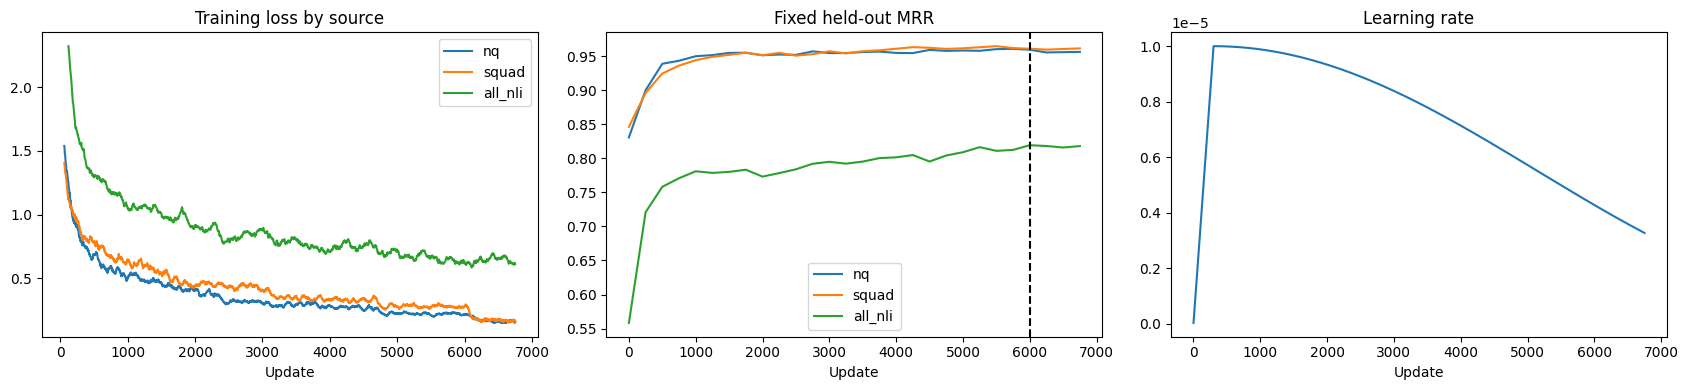

In [21]:
records={}
for line in (ROOT/'metrics.jsonl').read_text().splitlines():
    row=json.loads(line);records[row['step']]=row
records=[records[k] for k in sorted(records)]
fig,axes=plt.subplots(1,3,figsize=(17,4))
for name in corpus:
    rows=[r for r in records if r['source']==name]
    # Smooth within each source; losses from different tasks are not interchangeable.
    window=25
    if rows:
        loss=np.array([r['loss'] for r in rows]);smooth=np.convolve(loss,np.ones(min(window,len(loss)))/min(window,len(loss)),mode='valid')
        axes[0].plot([r['step'] for r in rows][-len(smooth):],smooth,label=name)
    val=[r for r in records if 'validation' in r]
    axes[1].plot([0]+[r['step'] for r in val],[BASE_VALIDATION['by_source'][name]['score']]+[r['validation']['by_source'][name]['score'] for r in val],label=name)
axes[0].set(title='Training loss by source',xlabel='Update');axes[0].legend()
axes[1].set(title='Fixed held-out MRR',xlabel='Update');axes[1].axvline(SELECTED['step'],color='black',ls='--');axes[1].legend()
axes[2].plot([r['step'] for r in records],[r['lr'] for r in records]);axes[2].set(title='Learning rate',xlabel='Update')
fig.tight_layout();fig.savefig(ROOT/'evaluations'/'training-curves.png',dpi=150);plt.show()

In [22]:
# Reference model uses the same tokenizer/pooling/length caps, with the exact starting weights.
reference=EmbeddingModel(copy.deepcopy(student.backbone).cpu(),student.tokenizer,student.output_dim,'ettin',student.spec)
reference.load_state_dict(BASE_WEIGHTS,strict=True);reference.to(DEVICE).eval()
COMPARISON=[]
for length in EVAL_LENGTHS:
    for model,label in [(reference,'source'),(student,'selected')]:
        model.max_length=length
        results=benchmark(model,f'{label}-{length}',dims=DIMS)
        for key,metrics in results.items():
            dataset,dim=key.rsplit('/',1)
            COMPARISON.append(dict(model=label,length=length,dataset=dataset,dimension=int(dim),**metrics))
student.max_length=CFG['max_length'];del reference;gc.collect();torch.cuda.empty_cache()
write_json(ROOT/'evaluations'/'before-after.json',dict(contract=CONTRACT_ID,selected=SELECTED,results=COMPARISON))
with open(ROOT/'evaluations'/'before-after.csv','w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(COMPARISON[0]));writer.writeheader();writer.writerows(COMPARISON)

source-256 NanoNQ 128 {'hit@1': 0.18, 'hit@5': 0.38, 'recall@10': 0.43, 'mrr@10': 0.263, 'ndcg@10': 0.294}
source-256 NanoNQ 256 {'hit@1': 0.16, 'hit@5': 0.38, 'recall@10': 0.45, 'mrr@10': 0.2579, 'ndcg@10': 0.2971}
source-256 NanoNQ 384 {'hit@1': 0.18, 'hit@5': 0.36, 'recall@10': 0.47, 'mrr@10': 0.2646, 'ndcg@10': 0.3045}
source-256 NanoHotpotQA 128 {'hit@1': 0.52, 'hit@5': 0.8, 'recall@10': 0.55, 'mrr@10': 0.6285, 'ndcg@10': 0.4872}
source-256 NanoHotpotQA 256 {'hit@1': 0.6, 'hit@5': 0.82, 'recall@10': 0.56, 'mrr@10': 0.6875, 'ndcg@10': 0.5266}
source-256 NanoHotpotQA 384 {'hit@1': 0.6, 'hit@5': 0.82, 'recall@10': 0.58, 'mrr@10': 0.6897, 'ndcg@10': 0.5341}
selected-256 NanoNQ 128 {'hit@1': 0.34, 'hit@5': 0.6, 'recall@10': 0.69, 'mrr@10': 0.4582, 'ndcg@10': 0.505}
selected-256 NanoNQ 256 {'hit@1': 0.38, 'hit@5': 0.66, 'recall@10': 0.71, 'mrr@10': 0.4932, 'ndcg@10': 0.5389}
selected-256 NanoNQ 384 {'hit@1': 0.38, 'hit@5': 0.62, 'recall@10': 0.68, 'mrr@10': 0.4862, 'ndcg@10': 0.5234}
se

## Export selected backbone and verify reload

Export one standard Transformers backbone and tokenizer, pooling/max-length metadata, selected-step identity and license provenance.
The GTE alignment head and optimizer are excluded. Future exit training must use this new backbone and adapt the old exit heads;
notebooks 04/05 are intentionally unchanged. `handoff.json` identifies the selected checkpoint and new mixed-data schema.

In [23]:
def load_export(path):
    path=Path(path);meta=json.loads((path/'encoder.json').read_text())
    tok=AutoTokenizer.from_pretrained(path/'tokenizer')
    backbone=AutoModel.from_pretrained(path/'backbone',attn_implementation='sdpa')
    model=EmbeddingModel(backbone,tok,meta['output_dim'],'ettin',meta['spec'])
    model.max_length=meta['max_length'];return model.to(DEVICE).eval()

EXPORT=ROOT/'exports'/f"backbone-step-{SELECTED['step']:08d}"
if not EXPORT.exists():
    tmp=ROOT/'exports'/('.uploading-'+uuid.uuid4().hex);tmp.mkdir(parents=True)
    student.backbone.save_pretrained(tmp/'backbone',safe_serialization=True);student.tokenizer.save_pretrained(tmp/'tokenizer')
    write_json(tmp/'encoder.json',dict(family='ettin',spec=student.spec,output_dim=student.output_dim,
        pooling='masked_mean_including_special_tokens',normalize=True,max_length=CFG['max_length'],dimensions=DIMS,
        contract=contract,selected=SELECTED,training_only_alignment_exported=False))
    shutil.copytree(NOTICE_DIR,tmp/'notices');write_json(tmp/'LICENSE_PROVENANCE.json',LICENSE_RECORD)
    write_json(tmp/'COMMITTED.json',dict(contract=CONTRACT_ID,checksums={str(p.relative_to(tmp)):file_sha(p) for p in sorted(tmp.rglob('*')) if p.is_file()}))
    os.replace(tmp,EXPORT)
manifest=json.loads((EXPORT/'COMMITTED.json').read_text());assert manifest['contract']==CONTRACT_ID
assert all(file_sha(EXPORT/p)==sha for p,sha in manifest['checksums'].items())
assert json.loads((EXPORT/'encoder.json').read_text())['selected']==SELECTED
reloaded=load_export(EXPORT)
probe=['Recover a forgotten password.','Books can be borrowed at the library.','This is a longer sentence. '*250]
for length in EVAL_LENGTHS:
    student.max_length=reloaded.max_length=length
    for dim in DIMS:torch.testing.assert_close(encode_texts(student,probe,dim=dim),encode_texts(reloaded,probe,dim=dim),atol=1e-5,rtol=1e-4)
student.max_length=CFG['max_length'];del reloaded;gc.collect();torch.cuda.empty_cache()
write_json(ROOT/'handoff.json',dict(export=str(EXPORT),checkpoint_stage='student',selected=SELECTED,
                                  data_file=str(DATA_DIR/'pairs.json'),data_schema='source -> split -> rows, pair holdouts / triplet training',
                                  next_step='Adapt notebooks 04/05 for this backbone and data schema; old exit weights require retraining.'))
print('Export/reload parity passed:',EXPORT)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/62 [00:00<?, ?it/s]

Export/reload parity passed: /content/drive/MyDrive/encoder_experiments/ettin-backbone-diverse-01/exports/backbone-step-00006000


## Final independent sanity check

Last cell: authored semantic probes, finite/nonzero outputs, repeatability and padding invariance at every dimension.
A synthetic long-input diagnostic places a relevant sentence at the beginning/middle/end of a passage; it reports scores
without imposing a fabricated semantic pass threshold. Use the held-out length-stratified retrieval for actual quality.

In [24]:
@torch.inference_mode()
def run_bottom_sanity(model, label):
    was_training = model.training
    model.eval()
    model_device = next(model.parameters()).device
    def encode_raw(texts):
        outputs = []
        for start in range(0,len(texts),4):
            ctx = torch.autocast('cuda',dtype=torch.bfloat16) if model_device.type == 'cuda' else nullcontext()
            with ctx:
                outputs.append(model(texts[start:start+4]).float().cpu())
        return torch.cat(outputs)
    try:
        # Same order as the scoring function: queries, positives, unrelated passages.
        texts = [row[column] for column in range(3) for row in SANITY_CASES]
        raw = encode_raw(texts)
        dimensions = sorted(set([d for d in (128,256,384) if d < raw.shape[1]] + [raw.shape[1]]))
        report = sanity_scores(raw,SANITY_CASES,dimensions)
        report.update(label=label, family=getattr(model,'family','unknown'),
                      contract=globals().get('CONTRACT_ID'), cases=len(SANITY_CASES),
                      candidate_passages=2*len(SANITY_CASES),
                      note='Small authored diagnostic. Truncated profiles are exploratory unless trained for them.')
        short = SANITY_CASES[0][0]
        long = 'This is a much longer passage about a library, its collection of books, the weather outside, and plans for a journey. '
        a = encode_raw([short]); repeated = encode_raw([short]); padded = encode_raw([short,long])[:1]
        repeat_ok = bool(torch.isfinite(a).all() and torch.isfinite(repeated).all() and
                         torch.allclose(a,repeated,atol=1e-5,rtol=1e-4))
        padding_by_dim={str(d):float(F.cosine_similarity(a[:,:d],padded[:,:d]).item()) for d in dimensions}
        padding_cosine=min(padding_by_dim.values())
        report['padding_cosines_by_dimension']=padding_by_dim
        report['repeatable'] = repeat_ok
        report['padding_cosine'] = padding_cosine
        report['plumbing_passed'] = bool(report['finite'] and report['nonzero'] and repeat_ok and
                                         padding_cosine is not None and padding_cosine > .999)
        flags = []
        for dim, metrics in report['profiles'].items():
            if not metrics['nonzero_prefix'] or metrics['normalized_spread'] < 1e-4:
                flags.append(f'{dim}D: zero or nearly collapsed embeddings.')
            if metrics['easy_accuracy'] <= .5:
                flags.append(f'{dim}D: easy semantic ranking at or below 50%; inspect examples.')
        report['flags'] = flags
        path = ROOT/'evaluations'/f'sanity-{time.time_ns()}.json'
        write_json(path,report)
        print('Plumbing:', 'PASS' if report['plumbing_passed'] else 'FAIL',
              '| repeatable:', repeat_ok, '| single/padded cosine:', padding_cosine)
        print(' dim   easy    hit@1   hit@5    margin    spread')
        for dim,metrics in report['profiles'].items():
            print(f"{dim:>4}  {metrics['easy_accuracy']:6.1%}  {metrics['hit_at_1']:6.1%}  "
                  f"{metrics['hit_at_5']:6.1%}  {metrics['mean_margin']:8.4f}  {metrics['normalized_spread']:8.4f}")
        if report['profiles']:
            print('\nFull-vector examples (positive should outrank unrelated):')
            for row in report['profiles'][str(raw.shape[1])]['examples']:
                print(f"{'OK' if row['easy_correct'] else 'MISS':4}  positive={row['positive_cosine']:.3f} "
                      f"unrelated={row['unrelated_cosine']:.3f} rank={row['positive_rank']:2}  {row['query']}")
        for flag in flags: print('Inspect:',flag)
        print('\nSaved to Drive:',path)
        print('Passing the plumbing checks does not establish semantic quality; use the retrieval benchmarks too.')
        if not report['plumbing_passed']:
            raise RuntimeError(f'Numerical, repeatability or padding check failed. Details: {path}')
        return report
    finally:
        model.train(was_training)


SANITY_MODEL=student;SANITY_LABEL=f"selected-backbone-step-{SELECTED['step']}"
sanity_report=run_bottom_sanity(SANITY_MODEL,SANITY_LABEL)
query=SANITY_CASES[0][0];fact=SANITY_CASES[0][1]
filler='The library has books about gardens, weather, music, and travel. '
# Fit the entire diagnostic, including the end-position fact, under the configured cap.
repeats=max(1,(CFG['max_length']-80)//len(student.tokenizer(filler,add_special_tokens=False)['input_ids']))
noise=filler*repeats
passages=[fact+' '+noise,noise[:len(noise)//2]+' '+fact+' '+noise[len(noise)//2:],noise+' '+fact,noise]
assert max(len(ids) for ids in student.tokenizer(passages)['input_ids'])<=CFG['max_length']
vectors=encode_texts(student,[query]+passages)
scores={str(d):(F.normalize(vectors[:1,:d],dim=-1)@F.normalize(vectors[1:,:d],dim=-1).T).squeeze(0).tolist() for d in DIMS}
write_json(ROOT/'evaluations'/'long-position-diagnostic.json',dict(selected=SELECTED,scores=scores,positions=['beginning','middle','end','unrelated'],
      note='Synthetic diagnostic only; no automatic quality threshold.',token_lengths=[len(x) for x in student.tokenizer(passages)['input_ids']]))
print('Long-position cosine scores [beginning, middle, end, unrelated]:',scores)

Plumbing: PASS | repeatable: True | single/padded cosine: 0.9999783635139465
 dim   easy    hit@1   hit@5    margin    spread
 128  100.0%   91.7%  100.0%    0.5650    0.8153
 256  100.0%   91.7%  100.0%    0.5275    0.7904
 384  100.0%   91.7%  100.0%    0.5009    0.7442

Full-vector examples (positive should outrank unrelated):
OK    positive=0.646 unrelated=0.111 rank= 1  I forgot my account password.
OK    positive=0.592 unrelated=0.161 rank= 1  How can I get my money back for this purchase?
OK    positive=0.626 unrelated=-0.008 rank= 1  My phone battery runs out too quickly.
OK    positive=0.668 unrelated=0.070 rank= 1  How do I bake a loaf of bread?
OK    positive=0.769 unrelated=0.172 rank= 1  I want to cancel my monthly subscription.
OK    positive=0.477 unrelated=0.061 rank= 1  My laptop cannot connect to Wi-Fi.
OK    positive=0.642 unrelated=0.203 rank= 1  How can I track the package I ordered?
OK    positive=0.684 unrelated=0.182 rank= 1  How do I change the language in the 

In [25]:
from google.colab import runtime
runtime.unassign()